# 📈 Predicting a Powerlifter's *Next* Meet Total

In the first notebook I predicted a total from bodyweight, sex, age and equipment alone (MAE ≈ 65 kg). The leftover error was mostly **training level**, which those features cannot see.

**This notebook adds history:** if we know a lifter's previous meets, how well can we predict their total at the next one?

**Plan**
1. Build one clean time-ordered career per lifter
2. Create history features (previous totals, layoff, experience, trend) using **only past meets**
3. Compare: naive "same as last time", rolling averages, Ridge, LightGBM
4. Break down accuracy by experience and see where it still fails

In [1]:
!unzip -o -q archive.zip

In [2]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
RNG = 42
def find(name):
    return (glob.glob(f'/kaggle/input/**/{name}', recursive=True) + glob.glob(f'**/{name}', recursive=True))[0]
df = pd.read_csv(find('openpowerlifting.csv')); meets = pd.read_csv(find('meets.csv'))
print(df.shape)

(386414, 17)


## 1. Clean and build careers
Same cleaning as before: keep full-power entries where total = squat + bench + deadlift. Then:
- **Drop duplicate rows:** a lifter entered in several divisions of one meet appears several times with the same lifts.
- **Define a career as (Name, Equipment).** Raw and equipped totals are not comparable, so a lifter who switches equipment starts a new series.

> ⚠️ Caveat: `Name` is not a unique ID, so two different people with the same name can be merged. This adds a little noise.

In [3]:
d = df.merge(meets[['MeetID','Federation','Date','MeetCountry']], on='MeetID', how='left')
d = d.dropna(subset=['TotalKg','BodyweightKg','BestSquatKg','BestBenchKg','BestDeadliftKg','Date'])
d = d[(d.BestSquatKg>0)&(d.BestBenchKg>0)&(d.BestDeadliftKg>0)&(d.TotalKg>0)]
d = d[(d.TotalKg-(d.BestSquatKg+d.BestBenchKg+d.BestDeadliftKg)).abs()<1.0]
d = d[d.BodyweightKg.between(30,250) & (d.Equipment!='Straps')]
d['Date'] = pd.to_datetime(d.Date)
n = len(d)
d = d.sort_values(['Name','Equipment','Date']).drop_duplicates(['Name','Equipment','MeetID'])
print(f'removed {n-len(d):,} duplicate division entries; {len(d):,} entries left')

# fill missing ages from a lifter's other known ages (shifted by elapsed years)
d['birth_est'] = d.Date.dt.year + d.Date.dt.dayofyear/365.25 - d.Age
d['birth_est'] = d.groupby('Name').birth_est.transform('median')
d['AgeFilled'] = (d.Date.dt.year + d.Date.dt.dayofyear/365.25 - d.birth_est)
d['AgeMissing'] = d.AgeFilled.isna().astype(int)
print(f'age now known for {d.AgeFilled.notna().mean():.0%} of rows (was {d.Age.notna().mean():.0%})')

g = d.groupby(['Name','Equipment'])
d['career_len'] = g.TotalKg.transform('size')
print('\ncareer lengths (meets per lifter-equipment):'); print(d.drop_duplicates(['Name','Equipment']).career_len.describe().round(1).to_dict())

removed 13,750 duplicate division entries; 271,796 entries left
age now known for 51% of rows (was 36%)

career lengths (meets per lifter-equipment):
{'count': 126240.0, 'mean': 2.2, 'std': 2.3, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 2.0, 'max': 82.0}


Age filling is a small bonus: if a lifter's age is recorded at *any* meet, we can infer it at their other meets. This lifts age coverage a lot.

## 2. History features (past only!)
For each meet the target is `TotalKg`. All history features come from the lifter's **earlier** meets via `shift`, so nothing from the current meet leaks in.

Only the **current bodyweight** is taken from the current meet, since it is known at weigh-in, before lifting.

In [4]:
g = d.groupby(['Name','Equipment'], sort=False)
d['prev_total']   = g.TotalKg.shift(1)
d['prev2_total']  = g.TotalKg.shift(2)
d['prev3_total']  = g.TotalKg.shift(3)
d['prev_bw']      = g.BodyweightKg.shift(1)
d['prev_date']    = g.Date.shift(1)
d['prev_sq']      = g.BestSquatKg.shift(1)
d['prev_bp']      = g.BestBenchKg.shift(1)
d['prev_dl']      = g.BestDeadliftKg.shift(1)
d['n_prior']      = g.cumcount()
# expanding stats of PRIOR totals only
d['prior_max']  = g.TotalKg.transform(lambda s: s.shift(1).expanding().max())
d['prior_mean'] = g.TotalKg.transform(lambda s: s.shift(1).expanding().mean())
d['roll3_mean'] = g.TotalKg.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

d['days_since']   = (d.Date - d.prev_date).dt.days
d['delta_prev']   = d.prev_total - d.prev2_total           # last gain/loss
d['bw_change']    = d.BodyweightKg - d.prev_bw
d['sq_share']     = d.prev_sq/d.prev_total
d['bp_share']     = d.prev_bp/d.prev_total
d['dl_share']     = d.prev_dl/d.prev_total
d['SexM']         = (d.Sex=='M').astype(int)
d['Year']         = d.Date.dt.year
for c in ['Equipment','Federation','MeetCountry']:
    d[c] = d[c].astype('category')

m = d.dropna(subset=['prev_total']).copy()     # need at least one prior meet
m = m[m.days_since > 0]
m['target_delta'] = m.TotalKg - m.prev_total
print(f'{len(m):,} predictable meets from {m.Name.nunique():,} lifters')
m[['TotalKg','prev_total','days_since','n_prior','delta_prev']].describe().round(1)

144,593 predictable meets from 50,333 lifters


,TotalKg,prev_total,days_since,n_prior,delta_prev
count,144593.0,144593.0,144593.0,144593.0,90522.0
mean,510.1,494.1,209.3,3.3,16.0
std,165.2,165.0,380.5,4.1,49.1
min,60.0,38.6,1.0,1.0,-746.3
25%,380.0,365.0,33.0,1.0,0.0
50%,507.5,490.0,125.0,2.0,15.0
75%,617.5,602.5,259.0,4.0,31.8
max,1365.3,1363.0,14315.0,81.0,692.5


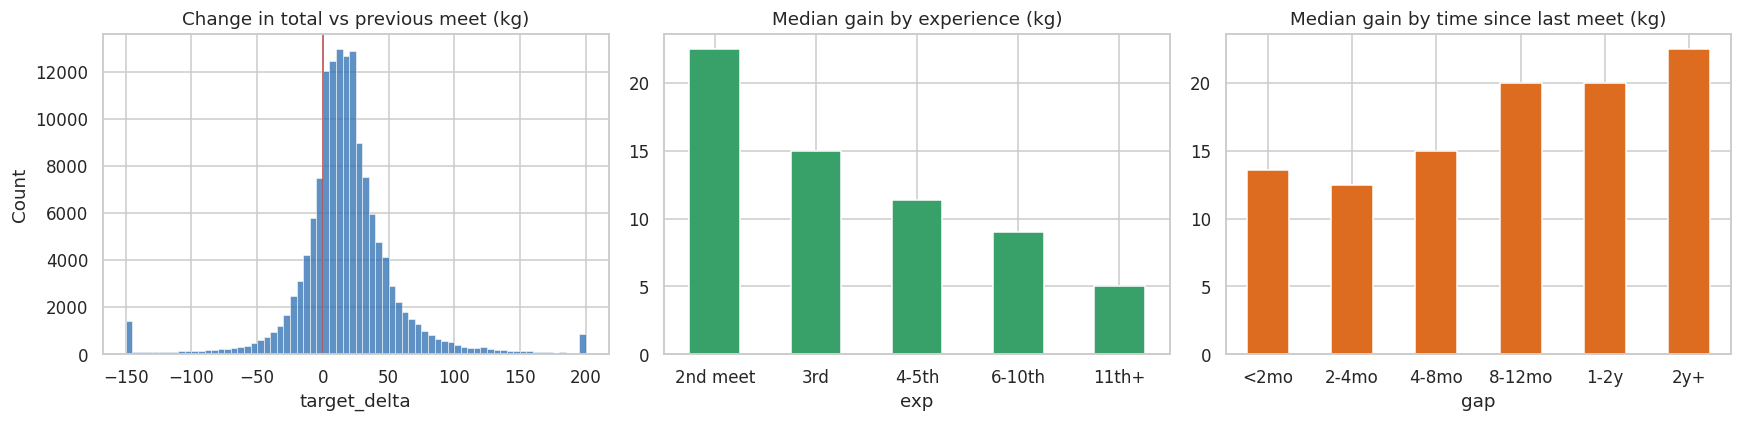

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(m.target_delta.clip(-150,200), bins=70, ax=ax[0], color='#2b6cb0'); ax[0].axvline(0,color='r',lw=1)
ax[0].set_title('Change in total vs previous meet (kg)')
b = m.assign(exp=pd.cut(m.n_prior, [0,1,2,4,9,100], labels=['2nd meet','3rd','4-5th','6-10th','11th+'])).groupby('exp', observed=True)
b.target_delta.median().plot.bar(ax=ax[1], color='#38a169'); ax[1].set_title('Median gain by experience (kg)'); ax[1].tick_params(axis='x', rotation=0)
m.assign(gap=pd.cut(m.days_since, [0,60,120,240,365,730,5000], labels=['<2mo','2-4mo','4-8mo','8-12mo','1-2y','2y+'])
         ).groupby('gap', observed=True).target_delta.median().plot.bar(ax=ax[2], color='#dd6b20')
ax[2].set_title('Median gain by time since last meet (kg)'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

Two clear patterns. **Newer lifters gain more** (novice gains: ~22 kg at the 2nd meet vs ~5 kg by the 11th). And **longer gaps between meets bring bigger median gains**, because there is more time to train, but also much more variability. The model should be able to learn both.

## 3. Split by lifter and set up features

In [6]:
FEATS = ['prev_total','prev2_total','prev3_total','prior_max','prior_mean','roll3_mean','delta_prev',
         'n_prior','days_since','BodyweightKg','prev_bw','bw_change','AgeFilled','AgeMissing',
         'sq_share','bp_share','dl_share','SexM','Year','Equipment','Federation','MeetCountry']
X, y, groups = m[FEATS], m.TotalKg, m.Name
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=RNG).split(X, y, groups))
Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(f'train {len(tr):,} | test {len(te):,} | shared lifters: {len(set(groups.iloc[tr])&set(groups.iloc[te]))}')

def report(name, p): return dict(model=name, MAE=mean_absolute_error(yte,p),
                                 RMSE=mean_squared_error(yte,p)**.5, R2=r2_score(yte,p))

train 115,772 | test 28,821 | shared lifters: 0


## 4. Models
Baselines first, because "same as last time" is hard to beat.

In [7]:
results, preds = [], {}
preds['last']  = Xte.prev_total.values;        results.append(report('Naive: same as last meet', preds['last']))
preds['best']  = Xte.prior_max.values;         results.append(report('Naive: best previous total', preds['best']))
preds['roll3'] = Xte.roll3_mean.values;        results.append(report('Mean of last 3 meets', preds['roll3']))

# Ridge on numeric history (predicting the change from last meet)
num = [c for c in FEATS if c not in ['Equipment','Federation','MeetCountry']]
med = Xtr[num].median()
Rtr = Xtr[num].fillna(med); Rte = Xte[num].fillna(med)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(Rtr, ytr - Xtr.prev_total)
preds['ridge'] = Xte.prev_total.values + ridge.predict(Rte); results.append(report('Ridge (predicts change)', preds['ridge']))

# LightGBM predicting the CHANGE from last meet, then adding it back
params = dict(objective='regression_l1' if False else 'regression', n_estimators=3000, learning_rate=.03, num_leaves=63,
              min_child_samples=40, subsample=.8, subsample_freq=1, colsample_bytree=.8, random_state=RNG, verbose=-1)
a_idx, v_idx = next(GroupShuffleSplit(n_splits=1, test_size=.15, random_state=RNG).split(Xtr, ytr, groups.iloc[tr]))
gbm = lgb.LGBMRegressor(**params)
dtr = ytr - Xtr.prev_total
gbm.fit(Xtr.iloc[a_idx], dtr.iloc[a_idx], eval_set=[(Xtr.iloc[v_idx], dtr.iloc[v_idx])],
        callbacks=[lgb.early_stopping(150, verbose=False)])
print('best iteration', gbm.best_iteration_)
preds['gbm'] = Xte.prev_total.values + gbm.predict(Xte); results.append(report('LightGBM (predicts change)', preds['gbm']))

res = pd.DataFrame(results).set_index('model').round(3); res

best iteration 1114


,MAE,RMSE,R2
model,,,
Naive: same as last meet,30.310,49.350,0.911
Naive: best previous total,30.754,51.390,0.904
Mean of last 3 meets,35.988,52.560,0.899
Ridge (predicts change),24.249,40.664,0.940
LightGBM (predicts change),21.894,36.144,0.952


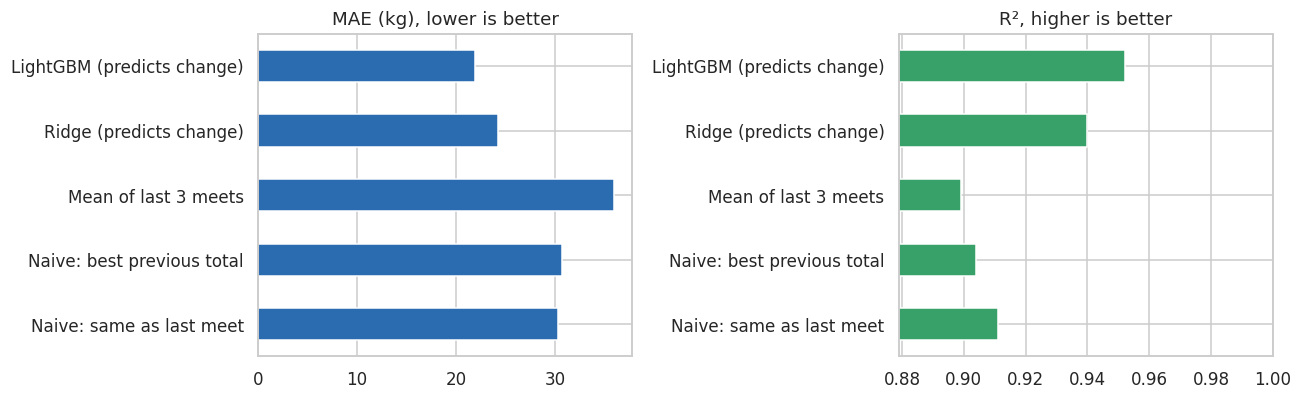

LightGBM with history: MAE 21.9 kg, R2 0.952


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
res.MAE.plot.barh(ax=ax[0], color='#2b6cb0'); ax[0].set_title('MAE (kg), lower is better'); ax[0].set_ylabel('')
res.R2.plot.barh(ax=ax[1], color='#38a169'); ax[1].set_title('R², higher is better'); ax[1].set_ylabel(''); ax[1].set_xlim(res.R2.min()-.02, 1)
plt.tight_layout(); plt.show()
print(f"LightGBM with history: MAE {res.loc['LightGBM (predicts change)','MAE']:.1f} kg, R2 {res.loc['LightGBM (predicts change)','R2']:.3f}")

## 5. Where does it work and where does it fail?

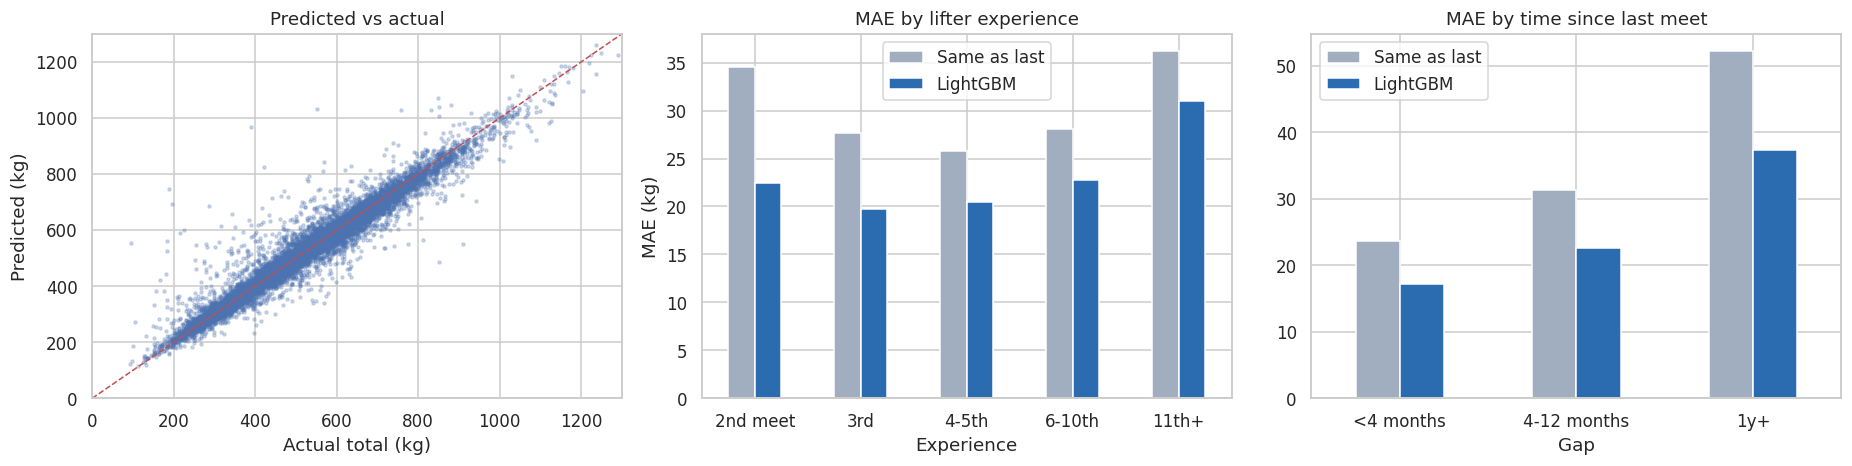

            Same as last  LightGBM
Experience                        
2nd meet            34.5      22.5
3rd                 27.7      19.7
4-5th               25.8      20.4
6-10th              28.1      22.8
11th+               36.2      31.0
             Same as last  LightGBM
Gap                                
<4 months            23.6      17.2
4-12 months          31.3      22.6
1y+                  52.2      37.3


In [9]:
best = preds['gbm']
ev = Xte.assign(y=yte.values, pred=best, naive=Xte.prev_total.values)
ev['gbm_err'] = (ev.y-ev.pred).abs(); ev['naive_err'] = (ev.y-ev.naive).abs()
ev['Experience'] = pd.cut(ev.n_prior, [0,1,2,4,9,100], labels=['2nd meet','3rd','4-5th','6-10th','11th+'])
ev['Gap'] = pd.cut(ev.days_since, [0,120,365,5000], labels=['<4 months','4-12 months','1y+'])
ev['Sex'] = np.where(ev.SexM==1,'M','F')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
s = np.random.RandomState(RNG).choice(len(ev), 15000, replace=False)
ax[0].scatter(ev.y.iloc[s], ev.pred.iloc[s], s=4, alpha=.25); ax[0].plot([0,1300],[0,1300],'r--',lw=1)
ax[0].set(xlabel='Actual total (kg)', ylabel='Predicted (kg)', title='Predicted vs actual', xlim=(0,1300), ylim=(0,1300))
t = ev.groupby('Experience', observed=True)[['naive_err','gbm_err']].mean().rename(columns={'naive_err':'Same as last','gbm_err':'LightGBM'})
t.plot.bar(ax=ax[1], color=['#a0aec0','#2b6cb0']); ax[1].set_title('MAE by lifter experience'); ax[1].tick_params(axis='x', rotation=0); ax[1].set_ylabel('MAE (kg)')
t2 = ev.groupby('Gap', observed=True)[['naive_err','gbm_err']].mean().rename(columns={'naive_err':'Same as last','gbm_err':'LightGBM'})
t2.plot.bar(ax=ax[2], color=['#a0aec0','#2b6cb0']); ax[2].set_title('MAE by time since last meet'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
print(t.round(1)); print(t2.round(1))

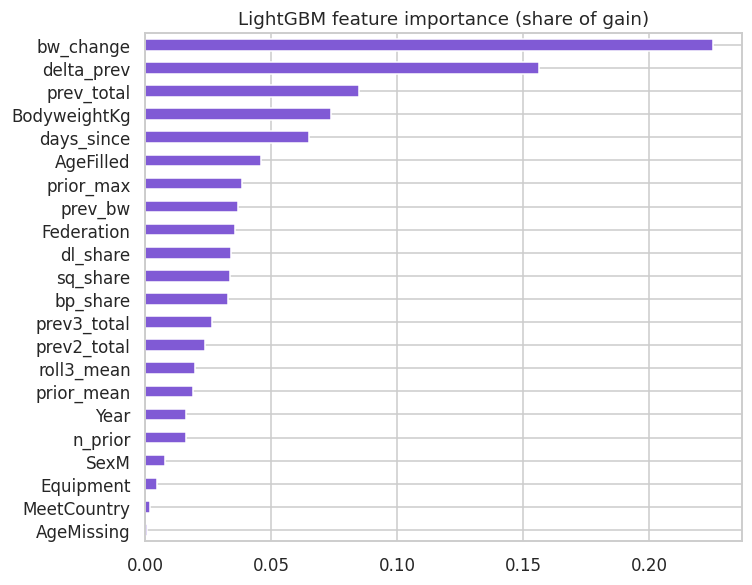

In [10]:
imp = pd.Series(gbm.booster_.feature_importance('gain'), index=FEATS).sort_values()
(imp/imp.sum()).plot.barh(figsize=(7,6), color='#805ad5'); plt.title('LightGBM feature importance (share of gain)'); plt.show()

### A few real lifters: prediction vs reality
Each line is one lifter from the held-out test set (never seen in training), predicted one meet at a time.

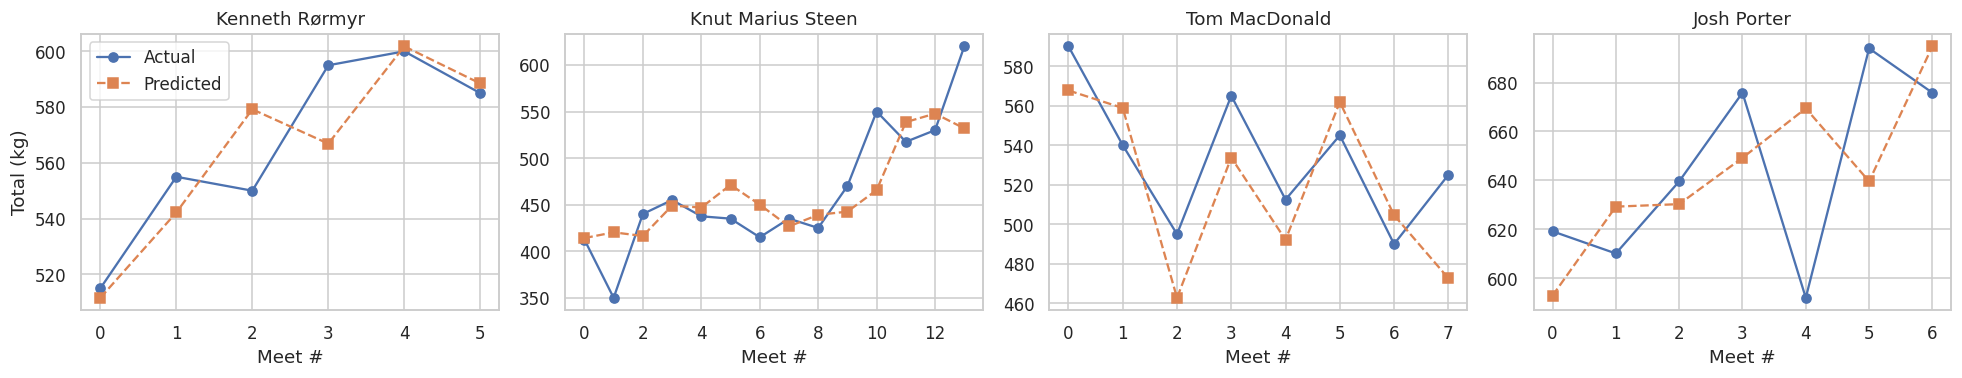

In [11]:
ev2 = ev.join(m[['Name','Date']])
cand = ev2.groupby('Name').size(); cand = cand[cand>=6].index
rs = np.random.RandomState(7); pick = rs.choice(cand, 4, replace=False)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=False)
for a, nm in zip(ax, pick):
    z = ev2[ev2.Name==nm].sort_values('Date')
    a.plot(range(len(z)), z.y, 'o-', label='Actual'); a.plot(range(len(z)), z.pred, 's--', label='Predicted')
    a.set_title(nm[:22]); a.set_xlabel('Meet #');
ax[0].set_ylabel('Total (kg)'); ax[0].legend(); plt.tight_layout(); plt.show()

## 6. Conclusions

In [12]:
r1 = res.loc['LightGBM (predicts change)']; r0 = res.loc['Naive: same as last meet']
print(f"Naive (same as last):  MAE {r0.MAE:.1f} kg")
print(f"LightGBM with history: MAE {r1.MAE:.1f} kg  ({1-r1.MAE/r0.MAE:.0%} better than naive), R2 {r1.R2:.3f}")
print("Rough reference: the no-history model in notebook 1 had MAE ~65 kg, but on a different set (all entries, not only lifters with 2+ meets), so treat that comparison as indicative only.")

Naive (same as last):  MAE 30.3 kg
LightGBM with history: MAE 21.9 kg  (28% better than naive), R2 0.952
Rough reference: the no-history model in notebook 1 had MAE ~65 kg, but on a different set (all entries, not only lifters with 2+ meets), so treat that comparison as indicative only.


**Takeaways**
- A lifter's own history is by far the best predictor of their next total. Even "same as last meet" (MAE ~30 kg) beats the demographics-only model from notebook 1 (MAE ~65 kg, on a different sample), which suggests most of that model's error was *training level*.
- The sensible baseline ("same as last time") is already strong, so the model's job is to predict the **change**, which is why modelling the delta works better than modelling the total directly.
- Gains depend on experience (novices improve fast) and on time between meets (longer gaps mean bigger but less predictable changes).
- The model beats the naive baseline at every experience level and gap length. Errors are smallest for lifters with a recent meet (under 4 months) and largest after gaps of a year or more, and also for veterans at their 11th+ meet, whose results are more erratic.

**Limitations and ideas**
- Name is not a unique ID, so a few careers are mixed up.
- Meets are irregular. Predicting for a fixed future date would need a different framing.
- Next steps: quantile regression for prediction **intervals**, predicting each lift separately, and adding weight-class changes or a lifter's age-curve position as features.